In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline
#show all columns
pd.set_option('display.max_columns', None)

In [2]:
# Loading the amazon uk dataset (assuming the file name is "amz_uk_price_prediction_dataset.csv")
RESULTS_DIR = "raw_data"

df = pd.read_csv(f"{RESULTS_DIR}/amz_uk_price_prediction_dataset.csv")


In [3]:
df.head

<bound method NDFrame.head of              uid        asin  \
0              1  B09B96TG33   
1              2  B01HTH3C8S   
2              3  B09B8YWXDF   
3              4  B09B8T5VGV   
4              5  B09WX6QD65   
...          ...         ...   
2443646  2828589  B0CHSD7P2Q   
2443647  2828590  B0B7B8FNBQ   
2443648  2828591  B0BD5FL5FB   
2443649  2828592  B008OYLL4I   
2443650  2828593  B08P3W9B3T   

                                                     title  stars  reviews  \
0        Echo Dot (5th generation, 2022 release) | Big ...    4.7    15308   
1        Anker Soundcore mini, Super-Portable Bluetooth...    4.7    98099   
2        Echo Dot (5th generation, 2022 release) | Big ...    4.7    15308   
3        Echo Dot with clock (5th generation, 2022 rele...    4.7     7205   
4        Introducing Echo Pop | Full sound compact Wi-F...    4.6     1881   
...                                                    ...    ...      ...   
2443646  Motorbike Armour, Motorbike Cl

In [4]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [5]:
df.dtypes

uid                    int64
asin                  object
title                 object
stars                float64
reviews                int64
price                float64
isBestSeller            bool
boughtInLastMonth      int64
category              object
dtype: object

---
## Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?



In [6]:
df["category"].nunique()

296

In [56]:
df['category'].value_counts().reset_index(name='count').rename(columns={'index': 'category'})

,category,count
0,Sports & Outdoors,836265
1,Beauty,19312
2,"Handmade Clothing, Shoes & Accessories",19229
3,Bath & Body,19092
4,Birthday Gifts,18978
...,...,...
291,Motorbike Chassis,107
292,Alexa Built-In Devices,107
293,Plugs,107
294,Smart Home Security & Lighting,104


The top 5 most listed categories are Sports & Outdoors, beauty, Handmade clothing, shoes & accesories, bath & body and birthday gifts.

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

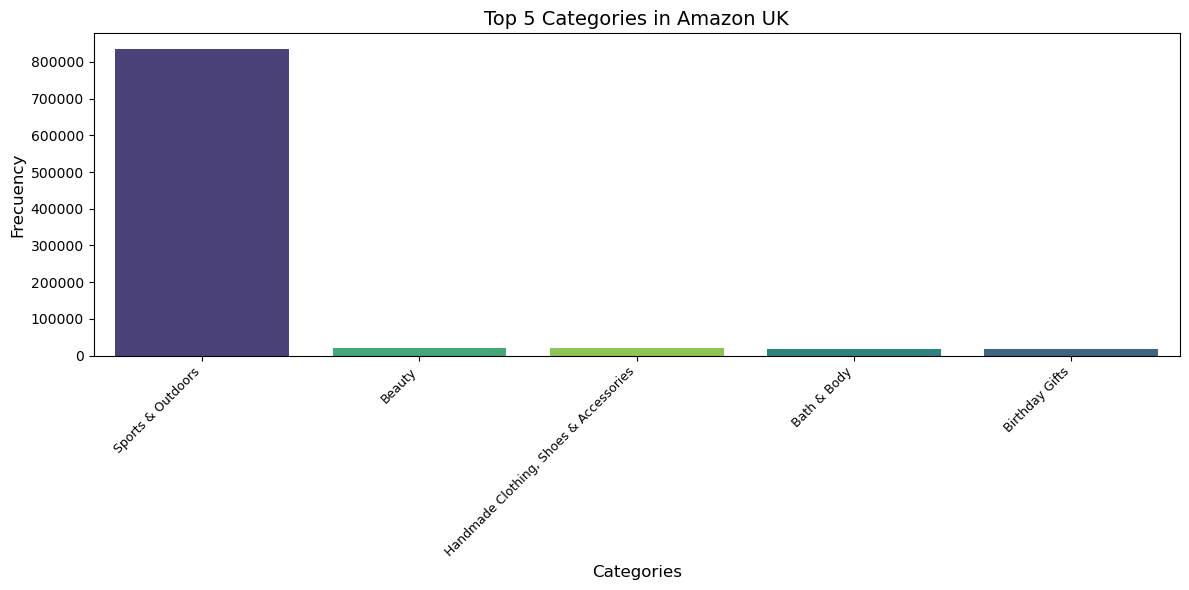

In [19]:
top_5 = df['category'].value_counts().nlargest(5).index
# Filter the main dataframe to only these countries
df_plot = df[df['category'].isin(top_5)]

plt.figure(figsize=(12, 6))

sns.countplot(
    data=df_plot, 
    x='category',  
    order=top_5,
    palette='viridis',  # Only if you want color distinction in categories
    dodge=False,
    hue='category',     # Adding hue to match palette
    legend=False        # Suppressing legend
)

# 3. Formatting
plt.title('Top 5 Categories in Amazon UK', fontsize=14)
plt.xlabel('Categories', fontsize=12)
plt.ylabel('Frecuency', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tick_params(axis='x', labelsize=9)

plt.tight_layout()
plt.show()

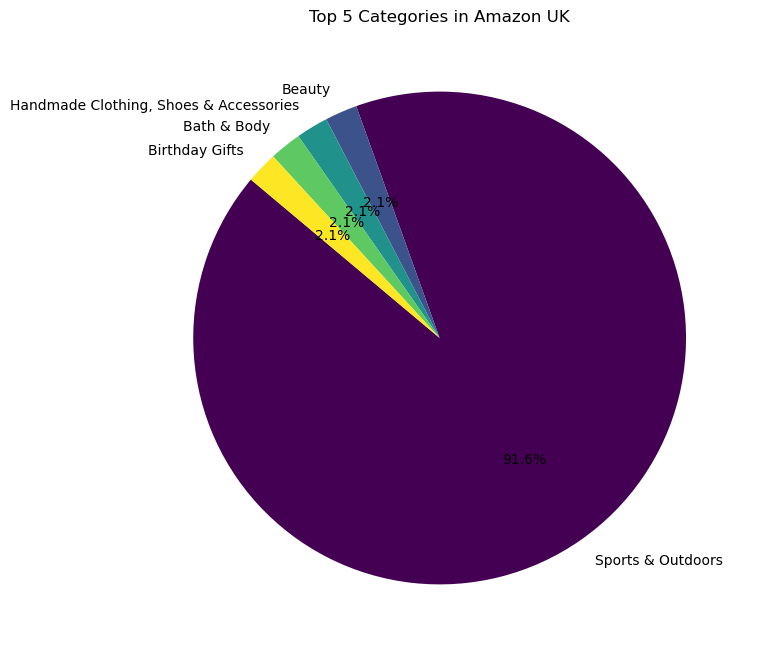

In [ ]:
top_5 = df['category'].value_counts().nlargest(5)

# Generate 5 distinct colors from viridis
colors = plt.cm.viridis(np.linspace(0, 1, len(top_5)))

plt.figure(figsize=(8, 8))
plt.pie(
    top_5.values,
    labels=top_5.index,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors
)

plt.title('Top 5 Categories in Amazon UK')
plt.show()

The main category is Sports & Outdoors with 91.6%

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 


In [73]:
print("Mean" " " , df["price"].mean().round(2))
print("Median" " " , df["price"].median())
print("Mode" " " , df["price"].mode())
print("The average price is 89.24 this is very high compare con the median 19.09 or the mode price 9.99 . Maybe due to some outliers in the data")

Mean  89.24
Median  19.09
Mode  0    9.99
Name: price, dtype: float64
The average price is 89.24 this is very high compare con the median 19.09 or the mode price 9.99 . Maybe due to some outliers in the data


In [63]:
stats = {"min": df["price"].min(),"max": df["price"].max(),"mean": df["price"].mean(), "range": df["price"].max() - df["price"].min(), 
         "std": df["price"].std(), "variance": df["price"].var(), "Q1": df['price'].quantile(0.25),"Q3": df['price'].quantile(0.75), "IQR": df['price'].quantile(0.75) - df['price'].quantile(0.25)}
for key, value in stats.items():
    if isinstance(value, float):
        print(f"{key}: {value:.2f}")
    else:
        print(f"{key}: {value}")

min: 0.00
max: 100000.00
mean: 89.24
range: 100000.00
std: 345.61
variance: 119445.49
Q1: 9.99
Q3: 45.99
IQR: 36.00


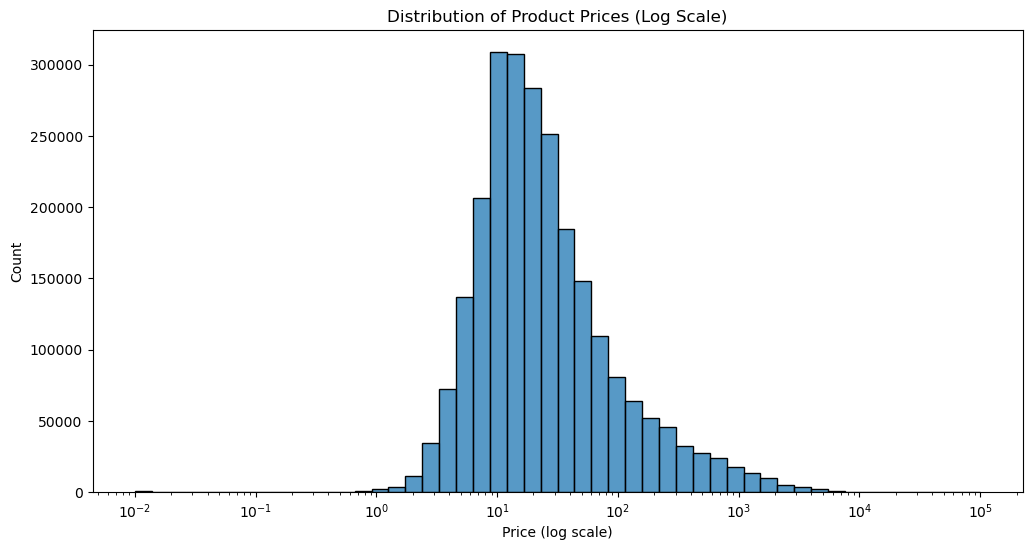

In [ ]:
plt.figure(figsize=(12,6))
sns.histplot(df['price'], bins=50, log_scale=True)
plt.title("Distribution of Product Prices (Log Scale)")
plt.xlabel("Price (log scale)")
plt.ylabel("Count")
plt.show()

The histogram using a logarithmic scale shows that most product prices are concentrated at the lower end, particularly below £50. The distribution is highly right-skewed, 
with a small number of very expensive products creating a long tail. A standard histogram is difficult to interpret due to these extreme values, but applying a log scale 
improves visibility by compressing the range of higher prices.

In [97]:
skewness_price = df['price'].skew()
kurtosis_price = df['price'].kurtosis()
print(skewness_price)
print(kurtosis_price)


27.492977566280338
4241.616412866518


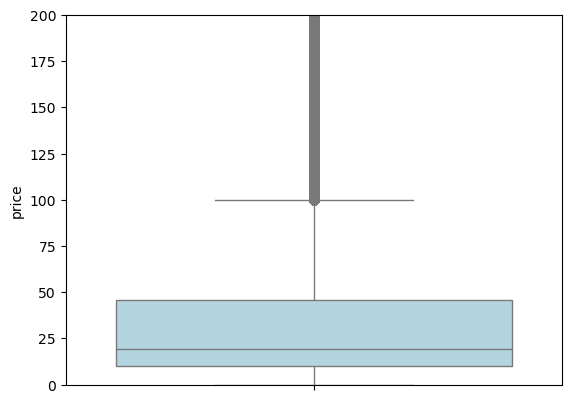

In [94]:
sns.boxplot(data=df['price'], color="lightblue")
plt.ylim(0, 200)  # focus on useful range
plt.show()

The column price contains several outliers. Because the price has a wider range that goes until 100000. Removing outliers can help to visualizing better the data.

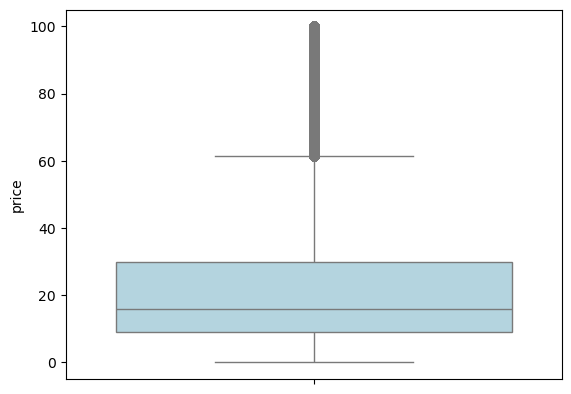

In [ ]:
#removing outliers
q1 = df['price'].quantile(0.25)
q3 = df['price'].quantile(0.75)
iqr = q3 - q1

df_clean = df[(df['price'] >= q1 - 1.5*iqr) & (df['price'] <= q3 + 1.5*iqr)]

sns.boxplot(data=df_clean['price'], color="lightblue")
plt.show()

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

In [83]:
print("Mean" " " , df["stars"].mean().round(2))
print("Median" " " , df["stars"].median())
print("Mode" " " , df["stars"].mode())
print("The average price is 480.63 this is very high compare con the median or the mode is 0. Maybe due to some outliers in the data")

Mean  2.15
Median  0.0
Mode  0    0.0
Name: stars, dtype: float64
The average price is 480.63 this is very high compare con the median or the mode is 0. Maybe due to some outliers in the data


In [82]:
df["stars"].nunique

<bound method IndexOpsMixin.nunique of 0          4.7
1          4.7
2          4.7
3          4.7
4          4.6
          ... 
2443646    0.0
2443647    0.0
2443648    0.0
2443649    4.3
2443650    4.5
Name: stars, Length: 2443651, dtype: float64>

Most customers don't rate the products (1225641). There are less reviews with lower stars >2.5 and most of the reviews have < 2.5 stars. In average the products recive 2.5 stars´

In [84]:
stats = {"min": df["stars"].min(),"max": df["stars"].max(),"mean": df["stars"].mean(), "range": df["stars"].max() - df["stars"].min(), 
         "std": df["stars"].std(), "variance": df["stars"].var(), "Q1": df["stars"].quantile(0.25),"Q3": df["stars"].quantile(0.75), "IQR": df["stars"].quantile(0.75) - df['stars'].quantile(0.25)}
for key, value in stats.items():
    if isinstance(value, float):
        print(f"{key}: {value:.2f}")
    else:
        print(f"{key}: {value}")

min: 0.00
max: 5.00
mean: 2.15
range: 5.00
std: 2.19
variance: 4.82
Q1: 0.00
Q3: 4.40
IQR: 4.40


In [ ]:
df['stars'].value_counts(ascending=True).sort_values()

stars
1.1          3
1.2         23
1.3         78
1.6        147
1.4        149
1.7        177
1.8        249
1.9        300
1.5        404
2.1        540
2.2        602
2.3        734
2.4       1060
2.6       1579
2.5       2103
2.7       2104
2.8       2306
2.9       3341
2.0       3901
3.1       4679
3.2       5771
3.3       8269
1.0       8484
3.4      10355
4.9      11081
3.0      12819
3.5      14673
3.6      16219
3.7      21137
3.8      27876
3.9      36555
4.8      41858
4.1      65115
4.0      66089
4.2      86871
4.7      94566
4.3     112564
5.0     128492
4.4     136165
4.6     136995
4.5     151577
0.0    1225641
Name: count, dtype: int64

There is a wider range of 5 between customers with an std of 2.19. 

In [98]:
skewness_price = df['stars'].skew()
kurtosis_price = df['stars'].kurtosis()
print(skewness_price)
print(kurtosis_price)

0.08120735761080985
-1.9260061280432985


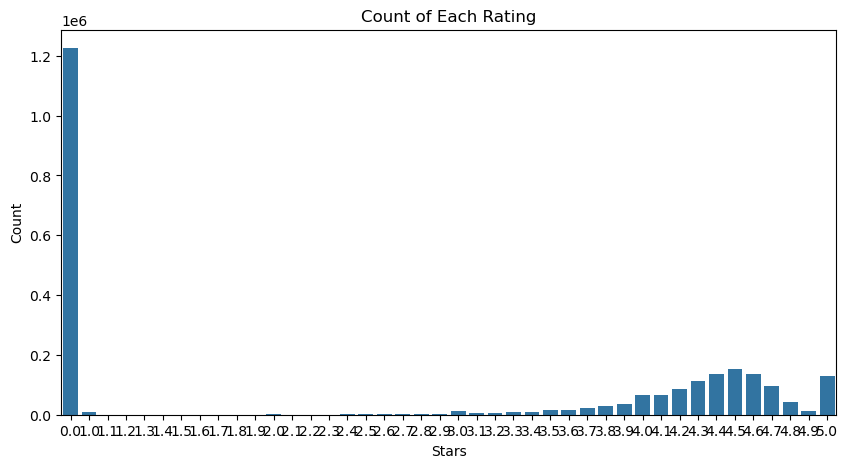

In [100]:
plt.figure(figsize=(10,5))
sns.countplot(x=df['stars'])

plt.title("Count of Each Rating")
plt.xlabel("Stars")
plt.ylabel("Count")

plt.show()

There isn't a real tendence, because some ratings are 0 creating two different Kurtosis and skewness. 